In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.pickle_functions import pickle_file_exists, load_from_pickle
from src.label_processing import update_labels
from src.hyperparam_processing import get_hyperparam_from_json

2023-11-23 15:40:03.270995: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2023-11-23 15:40:03.271015: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


### Useful functions

In [2]:
def get_y_fold_array(fold_list, fold_name, with_print=True):
    
    y_list = fold_list[1]
    y_array = np.reshape(np.array(y_list), (-1,6))
    if with_print:
        print("Shape for {} labels: {}".format(fold_name, y_array.shape))
    return y_array

In [3]:
def get_all_y_fold_array(param_task, task_name, all_scores):
    
    print("Task: {}\n".format(task_name))
    
    train_list = load_from_pickle("cmu_mosei_train", "raw_folds", "cmu_mosei")
    valid_list = load_from_pickle("cmu_mosei_valid", "raw_folds", "cmu_mosei")
    test_list = load_from_pickle("cmu_mosei_test",  "raw_folds", "cmu_mosei")
    
    param_task['label_type'] = task_name
    train_list, valid_list, test_list = update_labels(train_list, valid_list, test_list, param_task, all_scores)
    
    y_train_array = get_y_fold_array(train_list, "train")
    y_valid_array = get_y_fold_array(valid_list, "valid")
    y_test_array = get_y_fold_array(test_list, "test")
    y_all_array = np.concatenate((y_train_array, y_valid_array, y_test_array), axis=0)
    print("Shape for all labels: {}".format(y_all_array.shape))
    
    return y_train_array, y_valid_array, y_test_array, y_all_array

In [4]:
def get_df_from_y_array(y_array):
    df = pd.DataFrame(y_array, columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])
    return df

In [5]:
def get_all_scores():
    train_list = load_from_pickle("cmu_mosei_train", "raw_folds", "cmu_mosei")
    valid_list = load_from_pickle("cmu_mosei_valid", "raw_folds", "cmu_mosei")
    test_list = load_from_pickle("cmu_mosei_test",  "raw_folds", "cmu_mosei")
    
    y_train_array = get_y_fold_array(train_list, "train", with_print=False)
    y_valid_array = get_y_fold_array(valid_list, "valid", with_print=False)
    y_test_array = get_y_fold_array(test_list, "test", with_print=False)
    y_all_array = np.concatenate((y_train_array, y_valid_array, y_test_array), axis=0)
    
    all_scores = list(np.unique(y_all_array))
    
    return all_scores

In [6]:
def compute_unique(label, to_return):
    train_list = load_from_pickle("cmu_mosei_train", "raw_folds", "cmu_mosei")
    y_train_array = get_y_fold_array(train_list, "train", with_print=False)
    df = get_df_from_y_array(y_train_array)
    all_sc = list(df[label].unique())
    all_sc.sort()
    
    return all_sc

In [7]:
def print_compute_unique_scores():
    
    columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear']
    for col in columns:
        print("{}: {}\n".format(col, compute_unique(col, False))) 

In [8]:
def count_pairs_emotion_presence_score(y_array, all_scores):
    count_all = []
    for sc in all_scores:
        l = np.sum(y_array==sc, axis=0)
        count_all.append(l)
    count_all_arr = np.array(count_all)

    df_scores_all = pd.DataFrame(count_all_arr, 
                                 columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'],
                                 index=all_scores)
    
    return df_scores_all

### Parameters

In [9]:
param_training, param_task = get_hyperparam_from_json("param_training_task")

In [10]:
all_scores = get_all_scores()
print(all_scores)

[0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 0.8333333, 1.0, 1.1666666, 1.3333334, 1.5, 1.6666666, 2.0, 2.1666667, 2.3333333, 2.6666667, 3.0]


In [11]:
y_train_array_all, y_valid_array_all, y_test_array_all, y_all_array_all = \
get_all_y_fold_array(param_task, "all", all_scores)

Task: all

Shape for train labels: (16314, 6)
Shape for valid labels: (1870, 6)
Shape for test labels: (4652, 6)
Shape for all labels: (22836, 6)


In [12]:
y_train_array_pres, y_valid_array_pres, y_test_array_pres, y_all_array_pres = \
get_all_y_fold_array(param_task, "present", all_scores)

Task: present

Shape for train labels: (16314, 6)
Shape for valid labels: (1870, 6)
Shape for test labels: (4652, 6)
Shape for all labels: (22836, 6)


### List of scores

In [13]:
print_compute_unique_scores()

happiness: [0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 0.8333333, 1.0, 1.3333334, 1.6666666, 2.0, 2.1666667, 2.3333333, 2.6666667, 3.0]

sadness: [0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 0.8333333, 1.0, 1.1666666, 1.3333334, 1.5, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]

anger: [0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 1.0, 1.3333334, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]

surprise: [0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 1.0, 1.3333334, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]

disgust: [0.0, 0.33333334, 0.5, 0.6666667, 1.0, 1.3333334, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]

fear: [0.0, 0.16666667, 0.33333334, 0.6666667, 1.0, 1.3333334, 1.6666666]



# All data statistics

## Task: *all scores*

In [14]:
df_all_all = get_df_from_y_array(y_all_array_all)
df_all_all

,happiness,sadness,anger,surprise,disgust,fear
0,0.666667,0.666667,0.0,0.0,0.0,0.666667
1,0.000000,0.000000,0.0,0.0,0.0,0.000000
2,0.666667,0.666667,0.0,0.0,0.0,0.333333
3,0.333333,0.333333,0.0,0.0,0.0,0.000000
4,0.666667,0.000000,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...
22831,0.666667,0.000000,0.0,0.0,0.0,0.333333
22832,0.000000,0.000000,0.0,0.0,0.0,0.000000
22833,0.333333,0.000000,0.0,0.0,0.0,0.000000
22834,2.333333,0.000000,0.0,0.0,0.0,0.000000


In [15]:
df_all_all.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,22836.000000,22836.000000,22836.000000,22836.000000,22836.000000,22836.000000
mean,0.479561,0.158155,0.156010,0.048009,0.120103,0.041243
std,0.628671,0.325299,0.361424,0.168315,0.320473,0.152988
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.666667,0.333333,0.000000,0.000000,0.000000,0.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,1.666667


<AxesSubplot:>

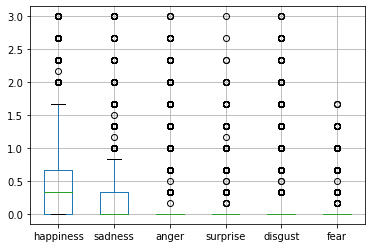

In [22]:
df_all_all.boxplot(column=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])

<AxesSubplot:title={'center':'Number of CMU-MOSEI samples per class and per presence score'}, ylabel='Frequency'>

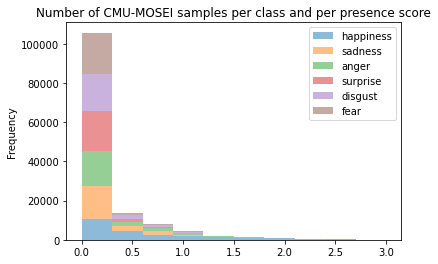

In [16]:
df_all_all.plot.hist(alpha=0.5, stacked=True,
                 title="Number of CMU-MOSEI samples per class and per presence score")

#### Get the number of samples for each pair (class, presence score)

In [17]:
df_scores_all_all = count_pairs_emotion_presence_score(y_all_array_all, all_scores)
df_scores_all_all

,happiness,sadness,anger,surprise,disgust,fear
0.000000,10606,16921,17905,20550,18796,20945
0.166667,23,12,1,5,0,12
0.333333,4347,2814,1942,1587,1876,1144
0.500000,9,3,1,2,2,1
0.666667,2594,1953,1361,490,1096,547
0.833333,6,1,0,0,0,0
1.000000,1772,732,1034,137,557,171
1.166667,3,1,0,1,0,0
1.333333,1315,231,290,36,252,13
1.500000,0,1,0,0,0,0


<AxesSubplot:title={'center':'Number of CMU-MOSEI samples per class and per presence score'}>

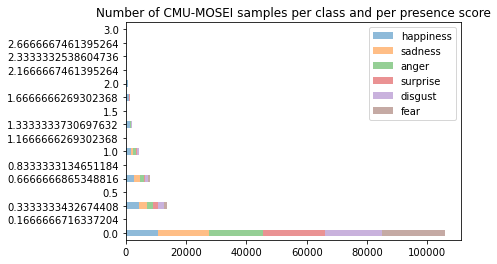

In [18]:
df_scores_all_all.plot.barh(alpha=0.5, stacked=True,
                      title="Number of CMU-MOSEI samples per class and per presence score")

<AxesSubplot:title={'center':'Number of CMU-MOSEI samples per class and per presence score'}>

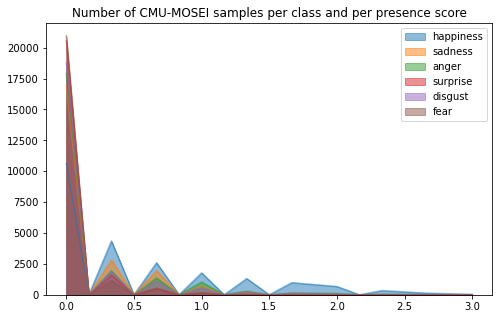

In [19]:
# df_scores_all_all.index.name = 'Presence score of the emotion'
df_scores_all_all.plot.area(stacked=False, figsize=(8,5),
                        title="Number of CMU-MOSEI samples per class and per presence score")

## Task: *present emotions*

In [57]:
df_all_pres = get_df_from_y_array(y_all_array_pres)
df_all_pres

,happiness,sadness,anger,surprise,disgust,fear
0,1,1,0,0,0,1
1,0,0,0,0,0,0
2,1,1,0,0,0,1
3,1,1,0,0,0,0
4,1,0,0,0,0,0
...,...,...,...,...,...,...
22831,1,0,0,0,0,1
22832,0,0,0,0,0,0
22833,1,0,0,0,0,0
22834,1,0,0,0,0,0


In [58]:
df_all_pres.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,22836.000000,22836.000000,22836.000000,22836.000000,22836.000000,22836.000000
mean,0.535558,0.259021,0.215931,0.100105,0.176914,0.082808
std,0.498745,0.438107,0.411476,0.300147,0.381604,0.275598
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [60]:
df_all_pres = count_pairs_emotion_presence_score(y_all_array_pres, [0,1])
df_all_pres

,happiness,sadness,anger,surprise,disgust,fear
0,10606,16921,17905,20550,18796,20945
1,12230,5915,4931,2286,4040,1891


<AxesSubplot:>

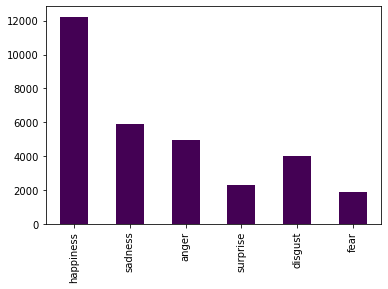

In [68]:
df_all_pres.iloc[1].plot(kind='bar', colormap='viridis')

# Training data statistics

## Task: *all scores*

In [23]:
df_train_all = get_df_from_y_array(y_train_array_all)
df_train_all

,happiness,sadness,anger,surprise,disgust,fear
0,0.666667,0.666667,0.0,0.0,0.0,0.666667
1,0.000000,0.000000,0.0,0.0,0.0,0.000000
2,0.666667,0.666667,0.0,0.0,0.0,0.333333
3,0.333333,0.333333,0.0,0.0,0.0,0.000000
4,0.666667,0.000000,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...
16309,0.000000,0.000000,0.0,0.0,0.0,0.000000
16310,0.000000,0.000000,0.0,0.0,0.0,0.000000
16311,1.000000,0.000000,0.0,0.0,0.0,0.000000
16312,0.333333,0.000000,0.0,0.0,0.0,0.000000


In [24]:
df_train_all.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,16314.000000,16314.000000,16314.000000,16314.000000,16314.000000,16314.000000
mean,0.487236,0.160986,0.157778,0.048843,0.124342,0.040497
std,0.640115,0.331295,0.367436,0.171970,0.327238,0.151937
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.666667,0.333333,0.000000,0.000000,0.000000,0.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,1.666667


<AxesSubplot:>

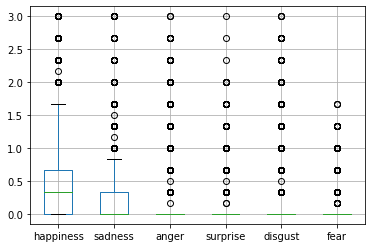

In [25]:
df_train_all.boxplot(column=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])

<AxesSubplot:title={'center':'Number of training samples per class and per presence score'}, ylabel='Frequency'>

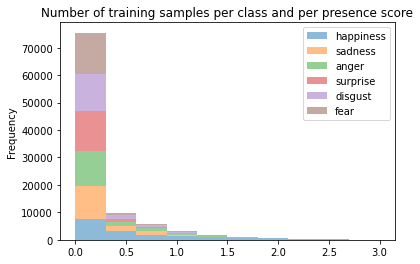

In [22]:
df_train_all.plot.hist(alpha=0.5, stacked=True,
            title="Number of training samples per class and per presence score")

#### Get the number of samples for each pair (class, presence score)

In [23]:
df_scores_train_all = count_pairs_emotion_presence_score(y_train_array_all, all_scores)
df_scores_train_all

,happiness,sadness,anger,surprise,disgust,fear
0.000000,7587,12047,12791,14672,13360,14984
0.166667,18,7,1,2,0,8
0.333333,3055,2023,1398,1133,1343,816
0.500000,7,2,1,1,1,0
0.666667,1825,1416,935,355,824,372
0.833333,2,1,0,0,0,0
1.000000,1252,506,736,100,393,121
1.166667,0,1,0,0,0,0
1.333333,949,176,212,26,195,10
1.500000,0,1,0,0,0,0


<AxesSubplot:title={'center':'Number of training samples per class and per presence score'}>

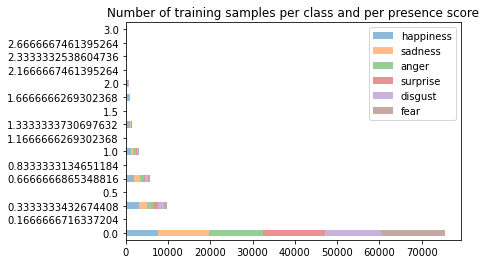

In [24]:
df_scores_train_all.plot.barh(alpha=0.5, stacked=True,
                          title="Number of training samples per class and per presence score")

<AxesSubplot:title={'center':'Number of training samples per class and per presence score'}>

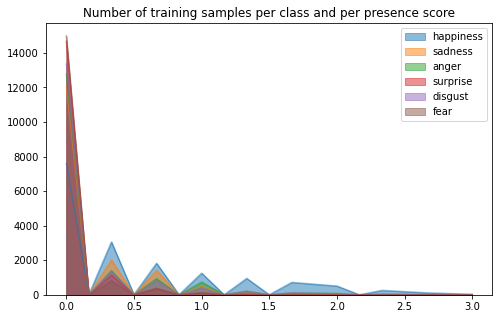

In [25]:
# df_scores_train_all.index.name = 'Presence score of the emotion'
df_scores_train_all.plot.area(stacked=False, figsize=(8,5), 
                          title="Number of training samples per class and per presence score")

## Task: *present emotions*

In [69]:
df_train_pres = get_df_from_y_array(y_train_array_pres)
df_train_pres

,happiness,sadness,anger,surprise,disgust,fear
0,1,1,0,0,0,1
1,0,0,0,0,0,0
2,1,1,0,0,0,1
3,1,1,0,0,0,0
4,1,0,0,0,0,0
...,...,...,...,...,...,...
16309,0,0,0,0,0,0
16310,0,0,0,0,0,0
16311,1,0,0,0,0,0
16312,1,0,0,0,0,0


In [70]:
df_train_pres.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,16314.000000,16314.000000,16314.000000,16314.000000,16314.000000,16314.000000
mean,0.534939,0.261554,0.215949,0.100650,0.181071,0.081525
std,0.498793,0.439495,0.411492,0.300874,0.385089,0.273648
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [71]:
df_train_pres = count_pairs_emotion_presence_score(y_train_array_pres, [0,1])
df_train_pres

,happiness,sadness,anger,surprise,disgust,fear
0,7587,12047,12791,14672,13360,14984
1,8727,4267,3523,1642,2954,1330


<AxesSubplot:>

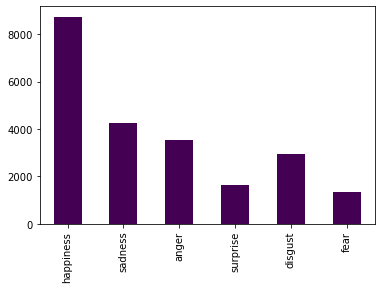

In [72]:
df_train_pres.iloc[1].plot(kind='bar', colormap='viridis')

# Validation data statistics

## Task: *all scores*

In [26]:
df_valid_all = get_df_from_y_array(y_valid_array_all)
df_valid_all

,happiness,sadness,anger,surprise,disgust,fear
0,0.666667,0.000000,0.0,0.0,0.000000,0.000000
1,0.000000,0.000000,0.0,0.0,0.000000,0.000000
2,0.333333,0.333333,0.0,0.0,0.000000,0.000000
3,0.333333,0.000000,0.0,0.0,0.000000,0.000000
4,0.000000,0.333333,0.0,0.0,0.000000,0.000000
...,...,...,...,...,...,...
1865,0.000000,0.000000,0.0,0.0,0.000000,0.000000
1866,0.333333,0.000000,0.0,0.0,0.000000,0.000000
1867,0.333333,0.000000,0.0,0.0,0.000000,0.000000
1868,0.333333,0.000000,0.0,0.0,0.000000,0.333333


In [27]:
df_valid_all.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,1870.000000,1870.000000,1870.000000,1870.000000,1870.000000,1870.000000
mean,0.439037,0.167469,0.122103,0.050357,0.089840,0.044118
std,0.578941,0.326644,0.303954,0.165471,0.263077,0.153140
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.666667,0.333333,0.000000,0.000000,0.000000,0.000000
max,3.000000,3.000000,2.333333,1.666667,2.666667,1.000000


<AxesSubplot:>

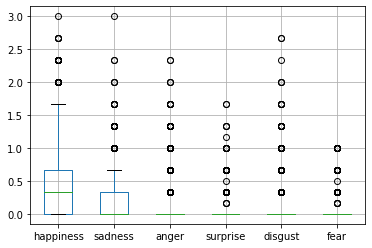

In [28]:
df_valid_all.boxplot(column=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])

<AxesSubplot:title={'center':'Number of validation samples per class and per presence score'}, ylabel='Frequency'>

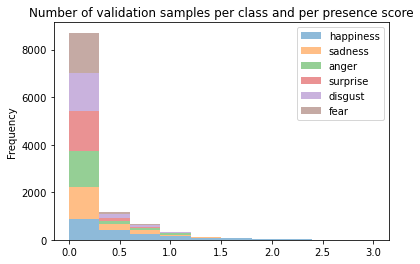

In [28]:
# df_valid_all.name = 'Presence score of the emotion'
df_valid_all.plot.hist(alpha=0.5, stacked=True,
            title="Number of validation samples per class and per presence score")

#### Get the number of samples for each pair (class, presence score)

In [29]:
df_scores_valid_all = count_pairs_emotion_presence_score(y_valid_array_all, all_scores)
df_scores_valid_all

,happiness,sadness,anger,surprise,disgust,fear
0.000000,865,1350,1532,1667,1589,1694
0.166667,4,3,0,3,0,4
0.333333,402,243,133,139,152,115
0.500000,1,0,0,1,0,1
0.666667,220,181,107,47,76,39
0.833333,4,0,0,0,0,0
1.000000,141,62,72,7,34,17
1.166667,3,0,0,1,0,0
1.333333,84,19,15,3,8,0
1.500000,0,0,0,0,0,0


<AxesSubplot:title={'center':'Number of validation samples per class and per presence score'}>

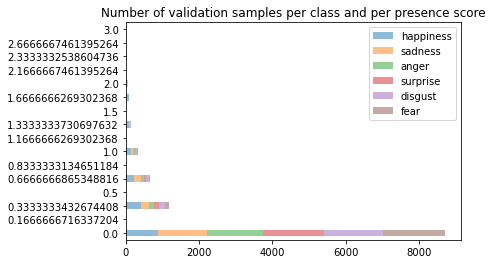

In [30]:
df_scores_valid_all.plot.barh(alpha=0.5, stacked=True,
                          title="Number of validation samples per class and per presence score")

<AxesSubplot:title={'center':'Number of validation samples per class and per presence score'}>

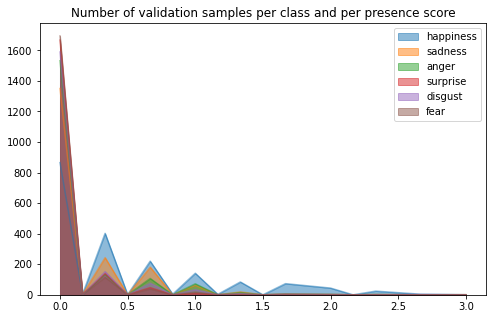

In [31]:
# df_scores_valid_all.index.name = 'Presence score of the emotion'
df_scores_valid_all.plot.area(stacked=False, figsize=(8,5), 
                         title="Number of validation samples per class and per presence score")

## Task: *present emotions*

In [73]:
df_valid_pres = get_df_from_y_array(y_valid_array_pres)
df_valid_pres

,happiness,sadness,anger,surprise,disgust,fear
0,1,0,0,0,0,0
1,0,0,0,0,0,0
2,1,1,0,0,0,0
3,1,0,0,0,0,0
4,0,1,0,0,0,0
...,...,...,...,...,...,...
1865,0,0,0,0,0,0
1866,1,0,0,0,0,0
1867,1,0,0,0,0,0
1868,1,0,0,0,0,1


In [74]:
df_valid_pres.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,1870.000000,1870.000000,1870.000000,1870.000000,1870.000000,1870.000000
mean,0.537433,0.278075,0.180749,0.108556,0.150267,0.094118
std,0.498730,0.448170,0.384913,0.311165,0.357429,0.292070
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [75]:
df_valid_pres = count_pairs_emotion_presence_score(y_valid_array_pres, [0,1])
df_valid_pres

,happiness,sadness,anger,surprise,disgust,fear
0,865,1350,1532,1667,1589,1694
1,1005,520,338,203,281,176


<AxesSubplot:>

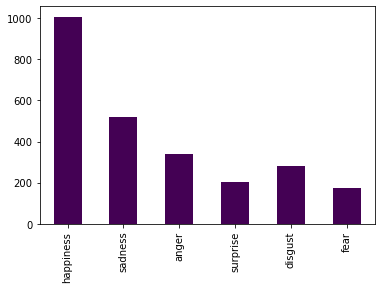

In [76]:
df_valid_pres.iloc[1].plot(kind='bar', colormap='viridis')

# Test data statistics

## Task: *all scores*

In [30]:
df_test_all = get_df_from_y_array(y_test_array_all)
df_test_all

,happiness,sadness,anger,surprise,disgust,fear
0,0.000000,0.333333,0.333333,0.0,0.0,0.000000
1,0.000000,0.333333,0.000000,0.0,0.0,0.000000
2,0.000000,0.333333,0.000000,0.0,0.0,0.000000
3,1.333333,0.000000,0.000000,0.0,0.0,0.000000
4,1.000000,0.000000,0.000000,0.0,0.0,0.000000
...,...,...,...,...,...,...
4647,0.666667,0.000000,0.000000,0.0,0.0,0.333333
4648,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4649,0.333333,0.000000,0.000000,0.0,0.0,0.000000
4650,2.333333,0.000000,0.000000,0.0,0.0,0.000000


In [31]:
df_test_all.describe(include='all')

,happiness,sadness,anger,surprise,disgust,fear
count,4652.000000,4652.000000,4652.000000,4652.000000,4652.000000,4652.000000
mean,0.468974,0.144490,0.163442,0.044139,0.117405,0.042706
std,0.606296,0.302431,0.360717,0.155825,0.317153,0.156531
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.666667,0.000000,0.000000,0.000000,0.000000,0.000000
max,3.000000,2.333333,3.000000,2.333333,3.000000,1.333333


<AxesSubplot:>

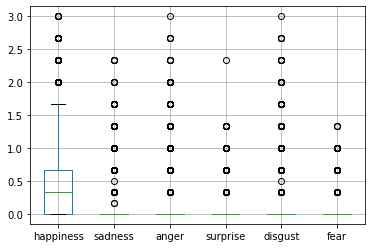

In [32]:
df_test_all.boxplot(column=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])

<AxesSubplot:title={'center':'Number of test samples per class and per presence score'}, ylabel='Frequency'>

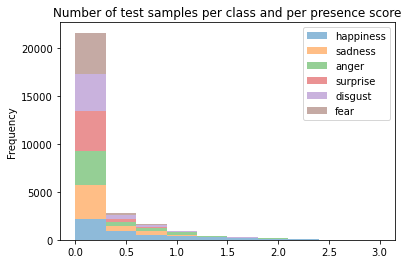

In [34]:
# df_test_all.name = 'Presence score of the emotion'
df_test_all.plot.hist(alpha=0.5, stacked=True,
            title="Number of test samples per class and per presence score")

#### Get the number of samples for each pair (class, presence score)

In [35]:
df_scores_test_all = count_pairs_emotion_presence_score(y_test_array_all, all_scores)
df_scores_test_all

,happiness,sadness,anger,surprise,disgust,fear
0.000000,2154,3524,3582,4211,3847,4267
0.166667,1,2,0,0,0,0
0.333333,890,548,411,315,381,213
0.500000,1,1,0,0,1,0
0.666667,549,356,319,88,196,136
0.833333,0,0,0,0,0,0
1.000000,379,164,226,30,130,33
1.166667,0,0,0,0,0,0
1.333333,282,36,63,7,49,3
1.500000,0,0,0,0,0,0


<AxesSubplot:title={'center':'Number of test samples per class and per presence score'}>

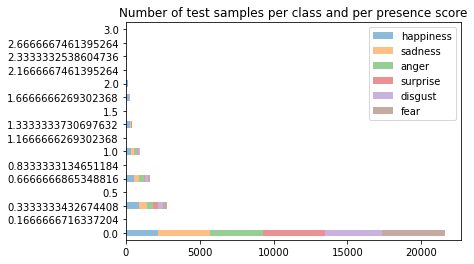

In [36]:
df_scores_test_all.plot.barh(alpha=0.5, stacked=True, 
                         title="Number of test samples per class and per presence score")

<AxesSubplot:title={'center':'Number of test samples per class and per presence score'}>

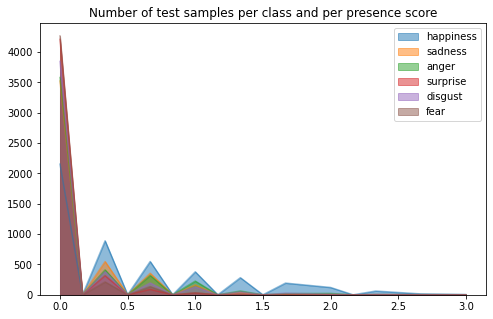

In [37]:
# df_scores_test_all.index.name = 'Presence score of the emotion'
df_scores_test_all.plot.area(stacked=False, figsize=(8,5), 
                         title="Number of test samples per class and per presence score")

## Task: *present emotions*

In [77]:
df_test_pres = get_df_from_y_array(y_test_array_pres)
df_test_pres

,happiness,sadness,anger,surprise,disgust,fear
0,0,1,1,0,0,0
1,0,1,0,0,0,0
2,0,1,0,0,0,0
3,1,0,0,0,0,0
4,1,0,0,0,0,0
...,...,...,...,...,...,...
4647,1,0,0,0,0,1
4648,0,0,0,0,0,0
4649,1,0,0,0,0,0
4650,1,0,0,0,0,0


In [78]:
df_test_pres.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,4652.000000,4652.000000,4652.000000,4652.000000,4652.000000,4652.000000
mean,0.536973,0.242476,0.230009,0.094798,0.173044,0.082760
std,0.498685,0.428627,0.420883,0.292967,0.378326,0.275549
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [79]:
df_test_pres = count_pairs_emotion_presence_score(y_test_array_pres, [0,1])
df_test_pres

,happiness,sadness,anger,surprise,disgust,fear
0,2154,3524,3582,4211,3847,4267
1,2498,1128,1070,441,805,385


<AxesSubplot:>

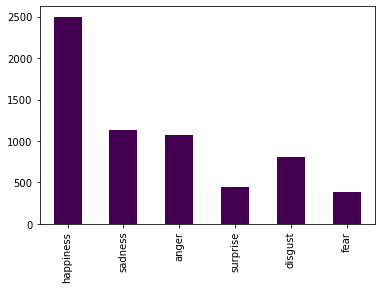

In [80]:
df_test_pres.iloc[1].plot(kind='bar', colormap='viridis')

# Diagram generation

Text(0.5, -0.2, 'Test')

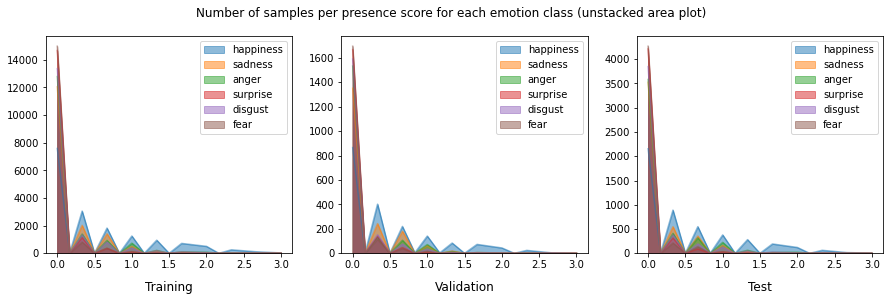

In [38]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Number of samples per presence score for each emotion class (unstacked area plot)')
df_scores_train_all.plot.area(ax=ax1, stacked=False, figsize=(15,4))
ax1.set_title("Training", y=-0.2)
df_scores_valid_all.plot.area(ax=ax2, stacked=False, figsize=(15,4))
ax2.set_title("Validation", y=-0.2)
df_scores_test_all.plot.area(ax=ax3, stacked=False, figsize=(15,4))
ax3.set_title("Test", y=-0.2)

Text(0, 0.5, '')

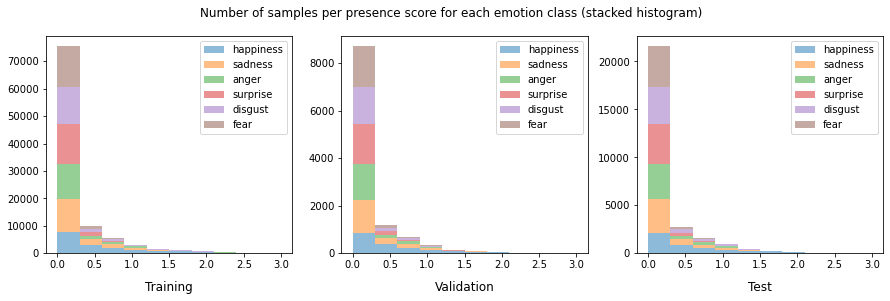

In [40]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Number of samples per presence score for each emotion class (stacked histogram)')
df_train_all.plot.hist(ax=ax1, alpha=0.5, stacked=True, figsize=(15,4), ylabel="")
ax1.set_title("Training", y=-0.2)
ax1.yaxis.set_label_text('') 
df_valid_all.plot.hist(ax=ax2, alpha=0.5, stacked=True, figsize=(15,4), ylabel="")
ax2.set_title("Validation", y=-0.2)
ax2.yaxis.set_label_text('') 
df_test_all.plot.hist(ax=ax3, alpha=0.5, stacked=True, figsize=(15,4), ylabel="")
ax3.set_title("Test", y=-0.2)
ax3.yaxis.set_label_text('') 

Text(0, 0.5, '')

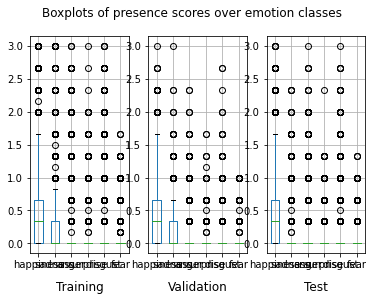

In [56]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Boxplots of presence scores over emotion classes')
df_train_all.boxplot(ax=ax1, figsize=(15,10), column=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])
ax1.set_title("Training", y=-0.2)
ax1.yaxis.set_label_text('') 
df_valid_all.boxplot(ax=ax2, figsize=(15,10), column=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])
ax2.set_title("Validation", y=-0.2)
ax2.yaxis.set_label_text('') 
df_test_all.boxplot(ax=ax3, figsize=(15,10), column=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])
ax3.set_title("Test", y=-0.2)
ax3.yaxis.set_label_text('') 

Text(0, 0.5, '')

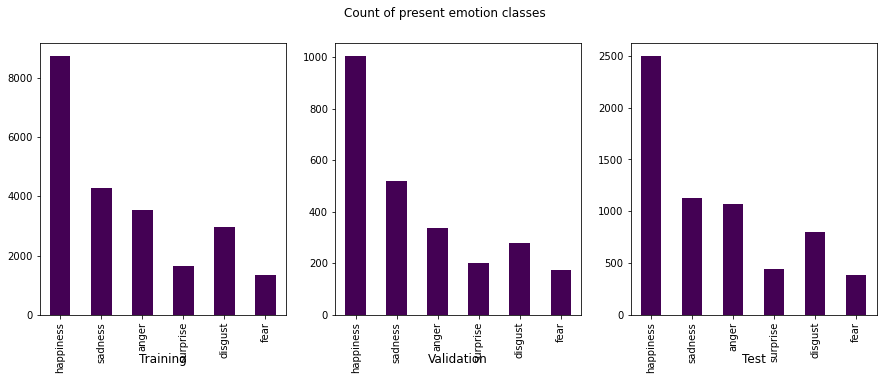

In [84]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Count of present emotion classes')
df_train_pres.iloc[1].plot(ax=ax1, figsize=(15,5), kind='bar', colormap='viridis')
ax1.set_title("Training", y=-0.2)
ax1.yaxis.set_label_text('') 
df_valid_pres.iloc[1].plot(ax=ax2, figsize=(15,5), kind='bar', colormap='viridis')
ax2.set_title("Validation", y=-0.2)
ax2.yaxis.set_label_text('') 
df_test_pres.iloc[1].plot(ax=ax3, figsize=(15,5), kind='bar', colormap='viridis')
ax3.set_title("Test", y=-0.2)
ax3.yaxis.set_label_text('') 